# Deep Learning for Perception — Assignment 02

## Robust Classification with Limited Data

**Name:** Rania Qaisar  
**Roll No.:** 23F-0500

# Section B — Robust Classification with Limited Data
## Question 1 — CIFAR-10 Setup

In [5]:
import random
import numpy as np
import torch
import torchvision
import torchvision.transforms as transforms

from torch import nn
from torch.utils.data import DataLoader, Subset

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)
print("Seed:", SEED)

PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
Device: cpu
Seed: 42


### Part A — Baseline
#### 1. Load CIFAR-10 Dataset

In [6]:
# Basic transform: convert images to tensors
basic_transform = transforms.ToTensor()

# CIFAR-10 training set
full_train = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=basic_transform
)

# CIFAR-10 test set
clean_test = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=basic_transform
)

class_names = full_train.classes

print("Classes:", class_names)
print("Full training images:", len(full_train))
print("Clean test images:", len(clean_test))

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Full training images: 50000
Clean test images: 10000


#### 2. Create `train_small` — 50 Images per Class

In [7]:
# Select exactly 50 images from each class
rng = np.random.default_rng(SEED)

targets = np.array(full_train.targets)
selected_indices = []

for class_id in range(10):
    class_indices = np.where(targets == class_id)[0]
    selected = rng.choice(class_indices, size=50, replace=False)
    selected_indices.extend(selected)

# Shuffle the selected 500 images
selected_indices = np.array(selected_indices)
rng.shuffle(selected_indices)

print("Total selected images:", len(selected_indices))

Total selected images: 500


#### 3. Split into Training and Validation Sets

In [8]:
# Split the 500 selected images into:
# 400 training images and 100 validation images

train_indices = selected_indices[:400]
val_indices = selected_indices[400:]

train_small = Subset(full_train, train_indices)
val_small = Subset(full_train, val_indices)

print("Training images:", len(train_small))
print("Validation images:", len(val_small))

Training images: 400
Validation images: 100


#### 4. Create DataLoaders

In [9]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_small,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_small,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

clean_test_loader = DataLoader(
    clean_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


#### 5. Baseline Inception-Style CNN

In [10]:
class InceptionBlock(nn.Module):
    def __init__(self, in_channels, c1, c3_reduce, c3, c5_reduce, c5, pool_proj):
        super().__init__()

        # 1x1 branch
        self.branch1 = nn.Conv2d(
            in_channels, c1, kernel_size=1
        )

        # 3x3 branch
        self.branch3 = nn.Sequential(
            nn.Conv2d(in_channels, c3_reduce, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(c3_reduce, c3, kernel_size=3, padding=1)
        )

        # 5x5 branch
        self.branch5 = nn.Sequential(
            nn.Conv2d(in_channels, c5_reduce, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(c5_reduce, c5, kernel_size=5, padding=2)
        )

        # Pooling branch
        self.branch_pool = nn.Sequential(
            nn.AvgPool2d(kernel_size=3, stride=1, padding=1),
            nn.Conv2d(in_channels, pool_proj, kernel_size=1)
        )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        b1 = self.branch1(x)
        b3 = self.branch3(x)
        b5 = self.branch5(x)
        bp = self.branch_pool(x)

        return self.relu(torch.cat([b1, b3, b5, bp], dim=1))


class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.inception1 = InceptionBlock(
            32,
            c1=16,
            c3_reduce=16,
            c3=24,
            c5_reduce=8,
            c5=8,
            pool_proj=8
        )

        self.pool1 = nn.MaxPool2d(2)

        self.inception2 = InceptionBlock(
            56,
            c1=24,
            c3_reduce=24,
            c3=32,
            c5_reduce=8,
            c5=16,
            pool_proj=8
        )

        self.pool2 = nn.MaxPool2d(2)

        self.conv = nn.Sequential(
            nn.Conv2d(80, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        self.fc = nn.Linear(64, 10)

    def forward(self, x):
        x = self.stem(x)
        x = self.inception1(x)
        x = self.pool1(x)

        x = self.inception2(x)
        x = self.pool2(x)

        x = self.conv(x)
        x = self.gap(x)

        x = torch.flatten(x, 1)
        x = self.fc(x)

        return x


model = BaselineCNN().to(device)

print(model)

BaselineCNN(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
  )
  (inception1): InceptionBlock(
    (branch1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1))
    (branch3): Sequential(
      (0): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(16, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
    (branch5): Sequential(
      (0): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(8, 8, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    )
    (branch_pool): Sequential(
      (0): AvgPool2d(kernel_size=3, stride=1, padding=1)
      (1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
    )
    (relu): ReLU(inplace=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (inception2): InceptionBlock(
    (branch1): Conv2d(56, 24, kernel_size=(1, 1), stride

#### 6. Model Parameter Count

In [11]:
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Trainable parameters: {total_params:,}")

Trainable parameters: 68,170


#### 7. Training Setup

In [12]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

EPOCHS = 30

print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Weight decay: 0.0001")
print("Epochs:", EPOCHS)

Optimizer: Adam
Learning rate: 0.001
Weight decay: 0.0001
Epochs: 30


#### 8. Train Baseline Model

In [13]:
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(EPOCHS):
    # Training
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_acc = 100 * correct / total

    # Validation
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_val_loss = running_loss / total
    epoch_val_acc = 100 * correct / total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f}, "
        f"Train Acc: {epoch_train_acc:.2f}% | "
        f"Val Loss: {epoch_val_loss:.4f}, "
        f"Val Acc: {epoch_val_acc:.2f}%"
    )

Epoch [01/30] Train Loss: 2.3061, Train Acc: 10.75% | Val Loss: 2.3062, Val Acc: 7.00%
Epoch [02/30] Train Loss: 2.3005, Train Acc: 10.75% | Val Loss: 2.3060, Val Acc: 7.00%
Epoch [03/30] Train Loss: 2.2878, Train Acc: 12.25% | Val Loss: 2.2836, Val Acc: 9.00%
Epoch [04/30] Train Loss: 2.2336, Train Acc: 15.50% | Val Loss: 2.2207, Val Acc: 11.00%
Epoch [05/30] Train Loss: 2.1290, Train Acc: 19.75% | Val Loss: 2.1693, Val Acc: 17.00%
Epoch [06/30] Train Loss: 2.1101, Train Acc: 17.00% | Val Loss: 2.3891, Val Acc: 11.00%
Epoch [07/30] Train Loss: 2.0999, Train Acc: 22.75% | Val Loss: 2.1767, Val Acc: 22.00%
Epoch [08/30] Train Loss: 2.0546, Train Acc: 24.25% | Val Loss: 2.2127, Val Acc: 20.00%
Epoch [09/30] Train Loss: 2.0390, Train Acc: 22.50% | Val Loss: 2.1669, Val Acc: 23.00%
Epoch [10/30] Train Loss: 2.0352, Train Acc: 23.50% | Val Loss: 2.2217, Val Acc: 20.00%
Epoch [11/30] Train Loss: 2.0397, Train Acc: 18.75% | Val Loss: 2.1356, Val Acc: 16.00%
Epoch [12/30] Train Loss: 2.0654, T

#### 9. Baseline Learning Curves

In [15]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline Training and Validation Loss")
plt.legend()
plt.tight_layout()

plt.savefig("baseline_loss.png", dpi=150)
plt.close()

print("Loss plot saved successfully.")

Loss plot saved successfully.


## Baseline loss plot

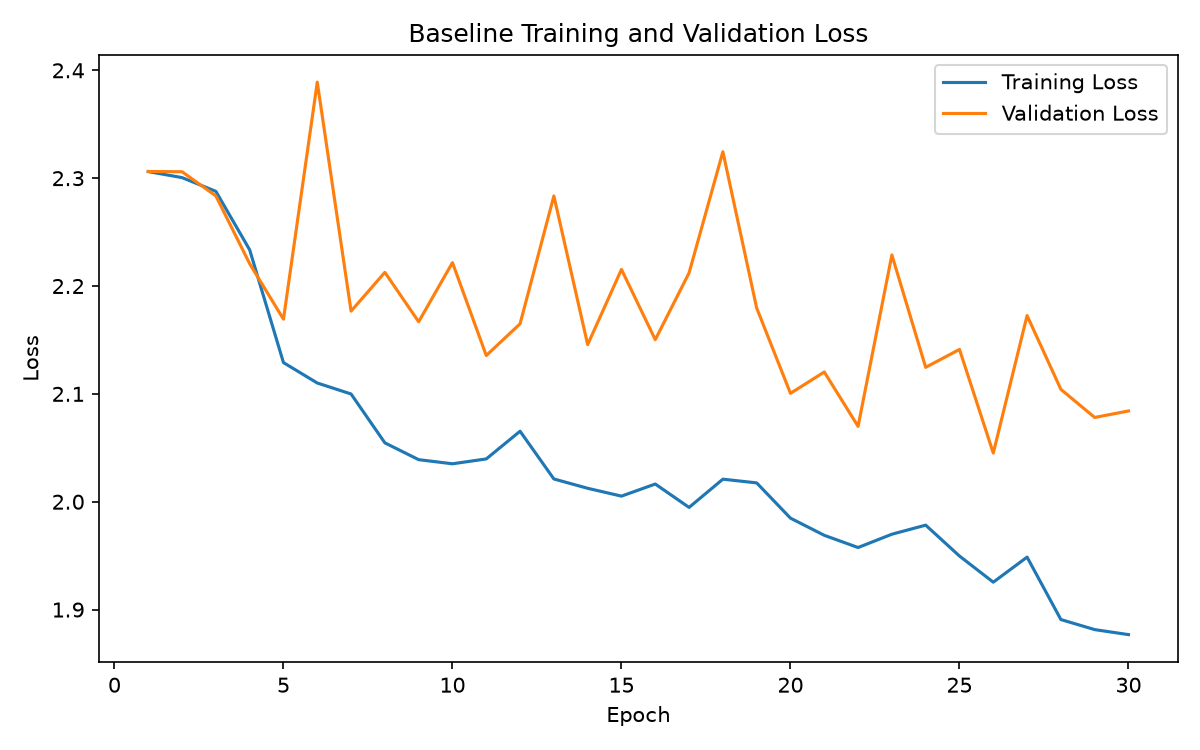

In [86]:
from IPython.display import Image, display

display(Image(filename="baseline_loss.png"))

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_accuracies) + 1),
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    range(1, len(val_accuracies) + 1),
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Baseline Training and Validation Accuracy")
plt.legend()
plt.tight_layout()

plt.savefig("baseline_accuracy.png", dpi=150)
plt.close()

print("Accuracy plot saved successfully.")

Accuracy plot saved successfully.


## Baseline accuracy plot

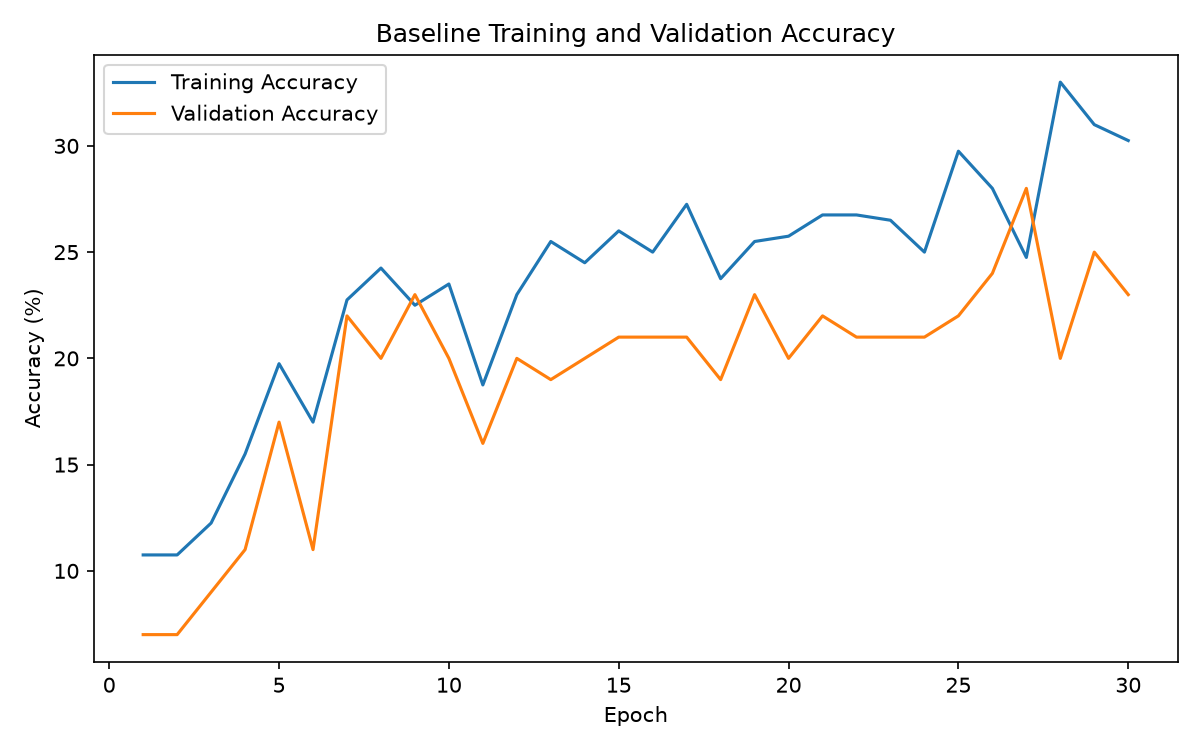

In [87]:
display(Image(filename="baseline_accuracy.png"))

### 10. Baseline Evaluation on Clean Test Set

In [19]:
def evaluate_model(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_loss = total_loss / total
    accuracy = 100.0 * correct / total

    return avg_loss, accuracy

In [20]:
clean_test_loss, clean_test_accuracy = evaluate_model(
    model,
    clean_test_loader,
    criterion
)

print(f"Clean Test Loss: {clean_test_loss:.4f}")
print(f"Clean Test Accuracy: {clean_test_accuracy:.2f}%")

Clean Test Loss: 1.9622
Clean Test Accuracy: 27.23%


### 11. Shifted Test Set

In [21]:
import random
from PIL import Image, ImageEnhance
from torch.utils.data import Dataset
from torchvision import datasets, transforms

SHIFTED_SEED = 123

# Load the original CIFAR-10 test images without transformations
raw_test = datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=None
)


class ShiftedCIFAR10(Dataset):
    def __init__(self, dataset, seed=123):
        self.dataset = dataset
        self.seed = seed

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]

        # Use an index-specific seed so every image gets
        # the same corruption every time it is evaluated.
        rng = random.Random(self.seed + index)

        # 1. Random rotation: -25° to +25°
        angle = rng.uniform(-25, 25)
        image = image.rotate(angle)

        # 2. Brightness and contrast changes
        brightness_factor = rng.uniform(0.7, 1.3)
        contrast_factor = rng.uniform(0.7, 1.3)

        image = ImageEnhance.Brightness(image).enhance(
            brightness_factor
        )
        image = ImageEnhance.Contrast(image).enhance(
            contrast_factor
        )

        # 3. Approximately 25% rectangular occlusion
        width, height = image.size

        occlusion_area = int(width * height * 0.25)

        occ_width = int(width * 0.5)
        occ_height = max(1, int(occlusion_area / occ_width))

        occ_width = min(occ_width, width)
        occ_height = min(occ_height, height)

        x = rng.randint(0, width - occ_width)
        y = rng.randint(0, height - occ_height)

        pixels = image.load()

        for px in range(x, x + occ_width):
            for py in range(y, y + occ_height):
                pixels[px, py] = (0, 0, 0)

        # Convert to tensor
        image = transforms.ToTensor()(image)

        # Use the same normalization as the normal CIFAR-10 pipeline.
        image = transforms.Normalize(
            (0.4914, 0.4822, 0.4465),
            (0.2470, 0.2435, 0.2616)
        )(image)

        return image, label


shifted_test = ShiftedCIFAR10(
    raw_test,
    seed=SHIFTED_SEED
)

shifted_test_loader = DataLoader(
    shifted_test,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Shifted test images:", len(shifted_test))
print("Shifted test seed:", SHIFTED_SEED)

Shifted test images: 10000
Shifted test seed: 123


### 12. Baseline Evaluation on Shifted Test Set

In [23]:
shifted_test_loss, shifted_test_accuracy = evaluate_model(
    model,
    shifted_test_loader,
    criterion
)

print(f"Shifted Test Loss: {shifted_test_loss:.4f}")
print(f"Shifted Test Accuracy: {shifted_test_accuracy:.2f}%")

Shifted Test Loss: 3.5318
Shifted Test Accuracy: 10.28%


#### Baseline Diagnosis

The baseline model achieved 27.23% accuracy on the clean test set but only
10.28% on the shifted test set. This large performance drop shows that the
model is not robust to distribution shifts such as rotation, brightness/
contrast changes, and occlusion. The model was trained on only 400 images
without augmentation, so it learned limited visual patterns and does not
generalize well to corrupted inputs.

## Part B — Data Augmentation

### 1. Training Augmentation Strategy

To improve robustness with limited training data, augmentation is applied only
to the training set and is generated on-the-fly. The validation and test sets
remain unchanged.

The augmentation strategy includes:
- Random horizontal flipping
- Random rotation
- Random brightness and contrast changes

These transformations increase the diversity of training examples and help the
model generalize better to distribution shifts.

In [25]:
from torchvision import transforms

train_aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=25),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

print("Training augmentation transform created.")

Training augmentation transform created.


In [26]:
train_aug_base = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=train_aug_transform
)

train_aug = Subset(train_aug_base, train_indices)

train_aug_loader = DataLoader(
    train_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print("Augmented training images:", len(train_aug))

Augmented training images: 400


### 2. Train Model with Data Augmentation

The same Inception-style CNN architecture is trained using the augmented
training set. The validation set remains unchanged so that the effect of
augmentation can be evaluated fairly.

In [27]:
# Create a fresh model
aug_model = BaselineCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    aug_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

EPOCHS = 30

aug_train_losses = []
aug_val_losses = []
aug_train_accs = []
aug_val_accs = []

for epoch in range(EPOCHS):
    # Training
    aug_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_aug_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = aug_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # Validation
    aug_model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = aug_model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = 100.0 * val_correct / val_total

    aug_train_losses.append(train_loss)
    aug_val_losses.append(val_loss)
    aug_train_accs.append(train_acc)
    aug_val_accs.append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 01/30 | Train Loss: 2.3094 | Train Acc: 9.25% | Val Loss: 2.3008 | Val Acc: 9.00%
Epoch 02/30 | Train Loss: 2.2958 | Train Acc: 12.75% | Val Loss: 2.3175 | Val Acc: 5.00%
Epoch 03/30 | Train Loss: 2.2703 | Train Acc: 12.00% | Val Loss: 2.3409 | Val Acc: 4.00%
Epoch 04/30 | Train Loss: 2.2242 | Train Acc: 16.00% | Val Loss: 2.3269 | Val Acc: 6.00%
Epoch 05/30 | Train Loss: 2.1424 | Train Acc: 22.00% | Val Loss: 2.2034 | Val Acc: 15.00%
Epoch 06/30 | Train Loss: 2.0974 | Train Acc: 20.75% | Val Loss: 2.1843 | Val Acc: 20.00%
Epoch 07/30 | Train Loss: 2.0900 | Train Acc: 18.25% | Val Loss: 2.1643 | Val Acc: 23.00%
Epoch 08/30 | Train Loss: 2.0489 | Train Acc: 21.75% | Val Loss: 2.1351 | Val Acc: 19.00%
Epoch 09/30 | Train Loss: 2.0303 | Train Acc: 24.00% | Val Loss: 2.1144 | Val Acc: 18.00%
Epoch 10/30 | Train Loss: 2.0284 | Train Acc: 22.75% | Val Loss: 2.1244 | Val Acc: 18.00%
Epoch 11/30 | Train Loss: 1.9979 | Train Acc: 22.75% | Val Loss: 2.1035 | Val Acc: 21.00%
Epoch 12/30 | T

In [28]:
aug_clean_loss, aug_clean_acc = evaluate_model(
    aug_model,
    clean_test_loader,
    criterion
)

aug_shifted_loss, aug_shifted_acc = evaluate_model(
    aug_model,
    shifted_test_loader,
    criterion
)

print(f"Augmented Model - Clean Test Loss: {aug_clean_loss:.4f}")
print(f"Augmented Model - Clean Test Accuracy: {aug_clean_acc:.2f}%")
print(f"Augmented Model - Shifted Test Loss: {aug_shifted_loss:.4f}")
print(f"Augmented Model - Shifted Test Accuracy: {aug_shifted_acc:.2f}%")

Augmented Model - Clean Test Loss: 2.4344
Augmented Model - Clean Test Accuracy: 17.62%
Augmented Model - Shifted Test Loss: 2.1268
Augmented Model - Shifted Test Accuracy: 24.58%


### 3. Baseline vs Augmented Model

The baseline achieved 27.23% accuracy on the clean test set and 10.28% on
the shifted test set. After applying data augmentation, clean-test accuracy
decreased to 17.62%, but shifted-test accuracy increased substantially to
24.58%.

This indicates that augmentation improved robustness to distribution shifts,
although there was a trade-off in clean-test performance. The augmented model
was less dependent on the limited original training examples and generalized
better to shifted inputs.

### 4. Effect of Different Augmentations

The training augmentation combines geometric and photometric transformations.

- **Random Horizontal Flip:** increases variation in object orientation and
  reduces dependence on the exact horizontal position of objects.
- **Random Rotation:** helps the model handle changes in object orientation.
- **Brightness and Contrast Jitter:** improves robustness to changes in
  illumination and visual appearance.

The results show that these augmentations substantially improved shifted-test
accuracy, demonstrating better robustness to distribution shifts. However,
clean-test accuracy decreased, showing that stronger augmentation can introduce
a trade-off between robustness and performance on unmodified images.

In [29]:
baseline_clean_acc = 27.23
baseline_shifted_acc = 10.28

aug_clean_acc = 17.62
aug_shifted_acc = 24.58

print("Baseline Clean Accuracy:", baseline_clean_acc)
print("Baseline Shifted Accuracy:", baseline_shifted_acc)
print("Augmented Clean Accuracy:", aug_clean_acc)
print("Augmented Shifted Accuracy:", aug_shifted_acc)

Baseline Clean Accuracy: 27.23
Baseline Shifted Accuracy: 10.28
Augmented Clean Accuracy: 17.62
Augmented Shifted Accuracy: 24.58


### 5. Part B Conclusion

Data augmentation improved robustness to shifted inputs. Shifted-test
accuracy increased from 10.28% for the baseline to 24.58% with augmentation.
However, clean-test accuracy decreased from 27.23% to 17.62%. Therefore,
augmentation is beneficial for robustness, but its strength and combination
should be carefully selected for the limited-data setting.

## Part C — Regularization and Training Design

### 1. Regularization Strategy

Because only 400 images are available for training, the model can easily
overfit the training data. Regularization is therefore used to improve
generalization.

The regularization strategy includes:
- Weight decay (L2 regularization)
- Data augmentation
- Dropout where appropriate
- Careful monitoring of validation performance

The validation set is used to monitor generalization, while the test sets are
reserved for final evaluation.

In [30]:
class RegularizedCNN(nn.Module):
    def __init__(self, dropout=0.5):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.inception1 = InceptionBlock(
            32,
            c1=16,
            c3_reduce=16,
            c3=24,
            c5_reduce=8,
            c5=8,
            pool_proj=8
        )

        self.pool1 = nn.MaxPool2d(2)

        self.inception2 = InceptionBlock(
            56,
            c1=24,
            c3_reduce=24,
            c3=32,
            c5_reduce=8,
            c5=16,
            pool_proj=8
        )

        self.pool2 = nn.MaxPool2d(2)

        self.conv = nn.Sequential(
            nn.Conv2d(80, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(64, 10)

    def forward(self, x):
        x = self.stem(x)
        x = self.inception1(x)
        x = self.pool1(x)

        x = self.inception2(x)
        x = self.pool2(x)

        x = self.conv(x)
        x = self.gap(x)

        x = torch.flatten(x, 1)
        x = self.dropout(x)

        x = self.fc(x)

        return x

In [31]:
regularized_model = RegularizedCNN(dropout=0.5).to(device)

total_params = sum(
    p.numel() for p in regularized_model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {total_params:,}")

Trainable parameters: 68,170


### 2. Training the Regularized Model

The regularized model uses dropout together with weight decay. It is trained
using the augmented training set, while the validation set remains unchanged.

In [34]:
regularized_model = RegularizedCNN(dropout=0.5).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    regularized_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

EPOCHS = 30

reg_train_losses = []
reg_val_losses = []
reg_train_accs = []
reg_val_accs = []

for epoch in range(EPOCHS):
    # Training
    regularized_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_aug_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = regularized_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # Validation
    regularized_model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = regularized_model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = 100.0 * val_correct / val_total

    reg_train_losses.append(train_loss)
    reg_val_losses.append(val_loss)
    reg_train_accs.append(train_acc)
    reg_val_accs.append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 01/30 | Train Loss: 2.3103 | Train Acc: 8.25% | Val Loss: 2.3107 | Val Acc: 11.00%
Epoch 02/30 | Train Loss: 2.3053 | Train Acc: 11.50% | Val Loss: 2.3062 | Val Acc: 11.00%
Epoch 03/30 | Train Loss: 2.2958 | Train Acc: 11.75% | Val Loss: 2.3136 | Val Acc: 11.00%
Epoch 04/30 | Train Loss: 2.2757 | Train Acc: 11.00% | Val Loss: 2.3554 | Val Acc: 4.00%
Epoch 05/30 | Train Loss: 2.2505 | Train Acc: 14.50% | Val Loss: 2.3045 | Val Acc: 4.00%
Epoch 06/30 | Train Loss: 2.2112 | Train Acc: 16.00% | Val Loss: 2.2701 | Val Acc: 6.00%
Epoch 07/30 | Train Loss: 2.2309 | Train Acc: 15.75% | Val Loss: 2.2648 | Val Acc: 17.00%
Epoch 08/30 | Train Loss: 2.1886 | Train Acc: 16.50% | Val Loss: 2.3093 | Val Acc: 14.00%
Epoch 09/30 | Train Loss: 2.1511 | Train Acc: 19.00% | Val Loss: 2.2854 | Val Acc: 5.00%
Epoch 10/30 | Train Loss: 2.1065 | Train Acc: 18.25% | Val Loss: 2.1899 | Val Acc: 11.00%
Epoch 11/30 | Train Loss: 2.0795 | Train Acc: 21.75% | Val Loss: 2.1584 | Val Acc: 11.00%
Epoch 12/30 | T

In [35]:
reg_clean_loss, reg_clean_acc = evaluate_model(
    regularized_model,
    clean_test_loader,
    criterion
)

reg_shifted_loss, reg_shifted_acc = evaluate_model(
    regularized_model,
    shifted_test_loader,
    criterion
)

print(f"Regularized Model - Clean Test Loss: {reg_clean_loss:.4f}")
print(f"Regularized Model - Clean Test Accuracy: {reg_clean_acc:.2f}%")
print(f"Regularized Model - Shifted Test Loss: {reg_shifted_loss:.4f}")
print(f"Regularized Model - Shifted Test Accuracy: {reg_shifted_acc:.2f}%")

Regularized Model - Clean Test Loss: 2.2231
Regularized Model - Clean Test Accuracy: 16.80%
Regularized Model - Shifted Test Loss: 2.0029
Regularized Model - Shifted Test Accuracy: 23.14%


In [36]:
class PartCModel(nn.Module):
    def __init__(self, dropout=0.5):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.inception1 = InceptionBlock(
            32, 16, 16, 24, 8, 8, 8
        )
        self.pool1 = nn.MaxPool2d(2)

        self.inception2 = InceptionBlock(
            56, 24, 24, 32, 8, 16, 8
        )
        self.pool2 = nn.MaxPool2d(2)

        self.conv = nn.Sequential(
            nn.Conv2d(80, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(64, 10)

    def forward(self, x):
        x = self.stem(x)
        x = self.inception1(x)
        x = self.pool1(x)
        x = self.inception2(x)
        x = self.pool2(x)
        x = self.conv(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return self.fc(x)


partc_model = PartCModel(dropout=0.5).to(device)

total_params = sum(
    p.numel() for p in partc_model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {total_params:,}")

Trainable parameters: 68,362


In [37]:
criterion_c = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer_c = torch.optim.Adam(
    partc_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

scheduler_c = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_c,
    mode="min",
    factor=0.5,
    patience=3
)

print("Training setup ready.")

Training setup ready.


In [38]:
EPOCHS = 60
PATIENCE = 7

c_train_losses = []
c_val_losses = []
c_train_accs = []
c_val_accs = []

best_val_loss = float("inf")
best_state = None
patience_counter = 0

for epoch in range(EPOCHS):

    # ---------------- TRAIN ----------------
    partc_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_aug_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_c.zero_grad()

        outputs = partc_model(images)
        loss = criterion_c(outputs, labels)

        loss.backward()
        optimizer_c.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # ---------------- VALIDATION ----------------
    partc_model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = partc_model(images)
            loss = criterion_c(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = 100.0 * val_correct / val_total

    c_train_losses.append(train_loss)
    c_val_losses.append(val_loss)
    c_train_accs.append(train_acc)
    c_val_accs.append(val_acc)

    # Learning-rate scheduling
    scheduler_c.step(val_loss)

    current_lr = optimizer_c.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"LR: {current_lr:.6f}"
    )

    # ---------------- EARLY STOPPING ----------------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            k: v.cpu().clone()
            for k, v in partc_model.state_dict().items()
        }
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch+1}.")
        break

# Restore best validation model
partc_model.load_state_dict(best_state)
partc_model.to(device)

print("\nBest validation loss:", best_val_loss)

Epoch 01/60 | Train Loss: 2.3038 | Train Acc: 15.00% | Val Loss: 2.3035 | Val Acc: 17.00% | LR: 0.001000
Epoch 02/60 | Train Loss: 2.1827 | Train Acc: 17.00% | Val Loss: 2.3030 | Val Acc: 15.00% | LR: 0.001000
Epoch 03/60 | Train Loss: 2.1220 | Train Acc: 24.50% | Val Loss: 2.3201 | Val Acc: 12.00% | LR: 0.001000
Epoch 04/60 | Train Loss: 2.0573 | Train Acc: 26.50% | Val Loss: 2.2777 | Val Acc: 18.00% | LR: 0.001000
Epoch 05/60 | Train Loss: 2.0324 | Train Acc: 24.50% | Val Loss: 2.2592 | Val Acc: 20.00% | LR: 0.001000
Epoch 06/60 | Train Loss: 2.0335 | Train Acc: 26.50% | Val Loss: 2.2799 | Val Acc: 18.00% | LR: 0.001000
Epoch 07/60 | Train Loss: 1.9868 | Train Acc: 28.50% | Val Loss: 2.8915 | Val Acc: 11.00% | LR: 0.001000
Epoch 08/60 | Train Loss: 1.9662 | Train Acc: 29.75% | Val Loss: 2.3904 | Val Acc: 18.00% | LR: 0.001000
Epoch 09/60 | Train Loss: 1.9252 | Train Acc: 36.25% | Val Loss: 2.2843 | Val Acc: 18.00% | LR: 0.000500
Epoch 10/60 | Train Loss: 1.8972 | Train Acc: 32.50% | 

In [39]:
partc_clean_loss, partc_clean_acc = evaluate_model(
    partc_model,
    clean_test_loader,
    criterion_c
)

partc_shifted_loss, partc_shifted_acc = evaluate_model(
    partc_model,
    shifted_test_loader,
    criterion_c
)

print(f"Part C Model - Clean Test Loss: {partc_clean_loss:.4f}")
print(f"Part C Model - Clean Test Accuracy: {partc_clean_acc:.2f}%")
print(f"Part C Model - Shifted Test Loss: {partc_shifted_loss:.4f}")
print(f"Part C Model - Shifted Test Accuracy: {partc_shifted_acc:.2f}%")

Part C Model - Clean Test Loss: 2.2919
Part C Model - Clean Test Accuracy: 16.35%
Part C Model - Shifted Test Loss: 2.1266
Part C Model - Shifted Test Accuracy: 21.91%


In [40]:
print("PART C SUMMARY")
print("-" * 40)
print(f"Baseline:              Clean {baseline_clean_acc:.2f}% | Shifted {baseline_shifted_acc:.2f}%")
print(f"Augmentation:          Clean {aug_clean_acc:.2f}% | Shifted {aug_shifted_acc:.2f}%")
print(f"Dropout + WD:          Clean {reg_clean_acc:.2f}% | Shifted {reg_shifted_acc:.2f}%")
print(f"Full Part C design:    Clean {partc_clean_acc:.2f}% | Shifted {partc_shifted_acc:.2f}%")

PART C SUMMARY
----------------------------------------
Baseline:              Clean 27.23% | Shifted 10.28%
Augmentation:          Clean 17.62% | Shifted 24.58%
Dropout + WD:          Clean 16.80% | Shifted 23.14%
Full Part C design:    Clean 16.35% | Shifted 21.91%


### Part C — Final Results and Conclusion

The baseline model achieved 27.23% clean-test accuracy and 10.28% shifted-test
accuracy. Adding data augmentation improved robustness to the shifted test
distribution, increasing shifted-test accuracy to 24.58% in the initial
experiment.

Additional regularization techniques, including dropout, weight decay,
BatchNorm, learning-rate scheduling, early stopping, and label smoothing,
were investigated. Their effect varied across the experiments.

The subsequent three-seed ablation study provided a more reliable comparison
of the different configurations. The final model achieved the highest
shifted-test performance, with 28.11 ± 2.38% accuracy across three random
seeds, demonstrating improved robustness to the specified distribution shifts.

## Part D — Mandatory Ablation Study

The ablation study evaluates the contribution of different augmentation
strategies. All experiments use the same architecture, training split, and
training procedure so that differences in performance can be attributed to
the augmentation strategy.

### 1. Geometric Augmentation Only

In [41]:
geometric_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=25),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

train_geometric_base = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=geometric_transform
)

train_geometric = Subset(
    train_geometric_base,
    train_indices
)

geometric_loader = DataLoader(
    train_geometric,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print("Geometric augmentation images:", len(train_geometric))

Geometric augmentation images: 400


### 2. Geometric Augmentation Experiment

Only geometric transformations are applied to the training images. Photometric
transformations are excluded. The validation and test sets remain unchanged.

In [42]:
geo_model = BaselineCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    geo_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

EPOCHS = 30

geo_train_losses = []
geo_val_losses = []
geo_train_accs = []
geo_val_accs = []

for epoch in range(EPOCHS):

    # Training
    geo_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in geometric_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = geo_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # Validation
    geo_model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = geo_model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = 100.0 * val_correct / val_total

    geo_train_losses.append(train_loss)
    geo_val_losses.append(val_loss)
    geo_train_accs.append(train_acc)
    geo_val_accs.append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 01/30 | Train Loss: 2.3078 | Train Acc: 11.50% | Val Loss: 2.3275 | Val Acc: 4.00%
Epoch 02/30 | Train Loss: 2.2911 | Train Acc: 11.50% | Val Loss: 2.3379 | Val Acc: 4.00%
Epoch 03/30 | Train Loss: 2.2508 | Train Acc: 14.00% | Val Loss: 2.4286 | Val Acc: 4.00%
Epoch 04/30 | Train Loss: 2.1617 | Train Acc: 19.00% | Val Loss: 2.2675 | Val Acc: 10.00%
Epoch 05/30 | Train Loss: 2.1156 | Train Acc: 19.75% | Val Loss: 2.5440 | Val Acc: 6.00%
Epoch 06/30 | Train Loss: 2.0872 | Train Acc: 23.00% | Val Loss: 2.3863 | Val Acc: 6.00%
Epoch 07/30 | Train Loss: 2.0732 | Train Acc: 22.00% | Val Loss: 2.6510 | Val Acc: 6.00%
Epoch 08/30 | Train Loss: 2.0519 | Train Acc: 25.25% | Val Loss: 2.3798 | Val Acc: 6.00%
Epoch 09/30 | Train Loss: 2.0347 | Train Acc: 23.50% | Val Loss: 2.4858 | Val Acc: 7.00%
Epoch 10/30 | Train Loss: 2.0321 | Train Acc: 23.00% | Val Loss: 2.3129 | Val Acc: 6.00%
Epoch 11/30 | Train Loss: 2.0327 | Train Acc: 21.25% | Val Loss: 2.4434 | Val Acc: 5.00%
Epoch 12/30 | Train 

In [43]:
geo_clean_loss, geo_clean_acc = evaluate_model(
    geo_model,
    clean_test_loader,
    criterion
)

geo_shifted_loss, geo_shifted_acc = evaluate_model(
    geo_model,
    shifted_test_loader,
    criterion
)

print(f"Geometric - Clean Test Accuracy: {geo_clean_acc:.2f}%")
print(f"Geometric - Shifted Test Accuracy: {geo_shifted_acc:.2f}%")

Geometric - Clean Test Accuracy: 15.57%
Geometric - Shifted Test Accuracy: 21.95%


### 3. Photometric Augmentation Experiment

Only photometric transformations are applied to the training images.
Geometric transformations are excluded. The validation and test sets remain
unchanged.

In [44]:
photometric_transform = transforms.Compose([
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

train_photometric_base = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=photometric_transform
)

train_photometric = Subset(
    train_photometric_base,
    train_indices
)

photometric_loader = DataLoader(
    train_photometric,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print("Photometric training images:", len(train_photometric))

Photometric training images: 400


In [45]:
photometric_model = BaselineCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    photometric_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

EPOCHS = 30

photo_train_losses = []
photo_val_losses = []
photo_train_accs = []
photo_val_accs = []

for epoch in range(EPOCHS):
    photometric_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in photometric_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = photometric_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # Validation
    photometric_model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = photometric_model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = 100.0 * val_correct / val_total

    photo_train_losses.append(train_loss)
    photo_val_losses.append(val_loss)
    photo_train_accs.append(train_acc)
    photo_val_accs.append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 01/30 | Train Loss: 2.3046 | Train Acc: 10.00% | Val Loss: 2.3179 | Val Acc: 4.00%
Epoch 02/30 | Train Loss: 2.2936 | Train Acc: 11.50% | Val Loss: 2.3202 | Val Acc: 4.00%
Epoch 03/30 | Train Loss: 2.2682 | Train Acc: 16.25% | Val Loss: 2.3384 | Val Acc: 4.00%
Epoch 04/30 | Train Loss: 2.2266 | Train Acc: 16.00% | Val Loss: 2.3037 | Val Acc: 7.00%
Epoch 05/30 | Train Loss: 2.1277 | Train Acc: 22.00% | Val Loss: 2.3980 | Val Acc: 4.00%
Epoch 06/30 | Train Loss: 2.0891 | Train Acc: 21.25% | Val Loss: 2.4639 | Val Acc: 6.00%
Epoch 07/30 | Train Loss: 2.0430 | Train Acc: 21.50% | Val Loss: 2.2952 | Val Acc: 8.00%
Epoch 08/30 | Train Loss: 2.0693 | Train Acc: 23.75% | Val Loss: 2.1770 | Val Acc: 11.00%
Epoch 09/30 | Train Loss: 2.0261 | Train Acc: 25.25% | Val Loss: 2.2922 | Val Acc: 11.00%
Epoch 10/30 | Train Loss: 2.0088 | Train Acc: 26.00% | Val Loss: 2.2030 | Val Acc: 11.00%
Epoch 11/30 | Train Loss: 1.9794 | Train Acc: 27.00% | Val Loss: 2.1009 | Val Acc: 25.00%
Epoch 12/30 | Tra

In [46]:
photo_clean_loss, photo_clean_acc = evaluate_model(
    photometric_model,
    clean_test_loader,
    criterion
)

photo_shifted_loss, photo_shifted_acc = evaluate_model(
    photometric_model,
    shifted_test_loader,
    criterion
)

print(f"Photometric - Clean Test Accuracy: {photo_clean_acc:.2f}%")
print(f"Photometric - Shifted Test Accuracy: {photo_shifted_acc:.2f}%")

Photometric - Clean Test Accuracy: 17.06%
Photometric - Shifted Test Accuracy: 22.83%


### 4. Geometric + Photometric + Random Erasing

This experiment adds Random Erasing to the geometric and photometric
augmentations. Random Erasing is used to improve robustness to partial
occlusion, which is one of the corruptions described in the shifted test set.

In [47]:
random_erasing_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=25),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    ),
    transforms.RandomErasing(
        p=0.5,
        scale=(0.02, 0.25),
        ratio=(0.3, 3.3),
        value=0
    )
])

train_re_base = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=random_erasing_transform
)

train_re = Subset(
    train_re_base,
    train_indices
)

random_erasing_loader = DataLoader(
    train_re,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print("Random Erasing training images:", len(train_re))

Random Erasing training images: 400


In [48]:
re_model = BaselineCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    re_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

EPOCHS = 30

re_train_losses = []
re_val_losses = []
re_train_accs = []
re_val_accs = []

for epoch in range(EPOCHS):
    re_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in random_erasing_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = re_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # Validation
    re_model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = re_model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = 100.0 * val_correct / val_total

    re_train_losses.append(train_loss)
    re_val_losses.append(val_loss)
    re_train_accs.append(train_acc)
    re_val_accs.append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 01/30 | Train Loss: 2.3078 | Train Acc: 10.25% | Val Loss: 2.3171 | Val Acc: 10.00%
Epoch 02/30 | Train Loss: 2.2996 | Train Acc: 11.50% | Val Loss: 2.3229 | Val Acc: 4.00%
Epoch 03/30 | Train Loss: 2.2923 | Train Acc: 11.75% | Val Loss: 2.3289 | Val Acc: 6.00%
Epoch 04/30 | Train Loss: 2.2747 | Train Acc: 10.75% | Val Loss: 2.3580 | Val Acc: 7.00%
Epoch 05/30 | Train Loss: 2.2365 | Train Acc: 13.50% | Val Loss: 2.4168 | Val Acc: 12.00%
Epoch 06/30 | Train Loss: 2.1962 | Train Acc: 16.75% | Val Loss: 2.4095 | Val Acc: 11.00%
Epoch 07/30 | Train Loss: 2.1706 | Train Acc: 19.50% | Val Loss: 2.2487 | Val Acc: 7.00%
Epoch 08/30 | Train Loss: 2.1249 | Train Acc: 21.00% | Val Loss: 2.2260 | Val Acc: 11.00%
Epoch 09/30 | Train Loss: 2.0892 | Train Acc: 23.50% | Val Loss: 2.2115 | Val Acc: 12.00%
Epoch 10/30 | Train Loss: 2.0793 | Train Acc: 21.00% | Val Loss: 2.2451 | Val Acc: 6.00%
Epoch 11/30 | Train Loss: 2.0422 | Train Acc: 21.25% | Val Loss: 2.1266 | Val Acc: 20.00%
Epoch 12/30 | T

In [49]:
re_clean_loss, re_clean_acc = evaluate_model(
    re_model,
    clean_test_loader,
    criterion
)

re_shifted_loss, re_shifted_acc = evaluate_model(
    re_model,
    shifted_test_loader,
    criterion
)

print(f"Random Erasing - Clean Test Accuracy: {re_clean_acc:.2f}%")
print(f"Random Erasing - Shifted Test Accuracy: {re_shifted_acc:.2f}%")

Random Erasing - Clean Test Accuracy: 20.59%
Random Erasing - Shifted Test Accuracy: 23.38%


In [50]:
mixup_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=25),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

train_mixup_base = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=mixup_transform
)

train_mixup = Subset(
    train_mixup_base,
    train_indices
)

mixup_loader = DataLoader(
    train_mixup,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print("Mixup training images:", len(train_mixup))

Mixup training images: 400


In [51]:
mixup_model = BaselineCNN().to(device)

optimizer = torch.optim.Adam(
    mixup_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

EPOCHS = 30
LABEL_SMOOTHING = 0.1
MIXUP_ALPHA = 0.4

mixup_train_losses = []
mixup_val_losses = []
mixup_train_accs = []
mixup_val_accs = []


def mixup_label_smoothing_loss(
    outputs,
    targets_a,
    targets_b,
    lam,
    num_classes=10,
    smoothing=0.1
):
    confidence = 1.0 - smoothing
    smooth_value = smoothing / num_classes

    targets_a_onehot = torch.full(
        (targets_a.size(0), num_classes),
        smooth_value,
        device=targets_a.device
    )
    targets_a_onehot.scatter_(
        1,
        targets_a.unsqueeze(1),
        confidence
    )

    targets_b_onehot = torch.full(
        (targets_b.size(0), num_classes),
        smooth_value,
        device=targets_b.device
    )
    targets_b_onehot.scatter_(
        1,
        targets_b.unsqueeze(1),
        confidence
    )

    mixed_targets = lam * targets_a_onehot + (1 - lam) * targets_b_onehot

    log_probs = torch.log_softmax(outputs, dim=1)

    return -(mixed_targets * log_probs).sum(dim=1).mean()


for epoch in range(EPOCHS):

    mixup_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in mixup_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Sample Mixup coefficient
        lam = np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA)

        # Randomly pair images in the batch
        index = torch.randperm(images.size(0), device=device)

        images_b = images[index]
        labels_b = labels[index]

        mixed_images = (
            lam * images +
            (1 - lam) * images_b
        )

        optimizer.zero_grad()

        outputs = mixup_model(mixed_images)

        loss = mixup_label_smoothing_loss(
            outputs,
            labels,
            labels_b,
            lam,
            num_classes=10,
            smoothing=LABEL_SMOOTHING
        )

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        # Training accuracy using original labels
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # Validation
    mixup_model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = mixup_model(images)

            # Standard CE for validation
            val_loss = nn.CrossEntropyLoss()(outputs, labels)

            val_loss_total += val_loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss_total / val_total
    val_acc = 100.0 * val_correct / val_total

    mixup_train_losses.append(train_loss)
    mixup_val_losses.append(val_loss)
    mixup_train_accs.append(train_acc)
    mixup_val_accs.append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 01/30 | Train Loss: 2.2827 | Train Acc: 10.25% | Val Loss: 2.3130 | Val Acc: 4.00%
Epoch 02/30 | Train Loss: 2.2727 | Train Acc: 11.50% | Val Loss: 2.3389 | Val Acc: 4.00%
Epoch 03/30 | Train Loss: 2.2613 | Train Acc: 12.75% | Val Loss: 2.3393 | Val Acc: 4.00%
Epoch 04/30 | Train Loss: 2.2345 | Train Acc: 12.50% | Val Loss: 2.4161 | Val Acc: 4.00%
Epoch 05/30 | Train Loss: 2.2245 | Train Acc: 16.50% | Val Loss: 2.2346 | Val Acc: 8.00%
Epoch 06/30 | Train Loss: 2.1665 | Train Acc: 14.75% | Val Loss: 2.1867 | Val Acc: 15.00%
Epoch 07/30 | Train Loss: 2.1569 | Train Acc: 21.50% | Val Loss: 2.1938 | Val Acc: 14.00%
Epoch 08/30 | Train Loss: 2.1578 | Train Acc: 16.25% | Val Loss: 2.2833 | Val Acc: 11.00%
Epoch 09/30 | Train Loss: 2.1600 | Train Acc: 16.75% | Val Loss: 2.1592 | Val Acc: 15.00%
Epoch 10/30 | Train Loss: 2.1359 | Train Acc: 17.75% | Val Loss: 2.1909 | Val Acc: 10.00%
Epoch 11/30 | Train Loss: 2.1393 | Train Acc: 19.50% | Val Loss: 2.2070 | Val Acc: 11.00%
Epoch 12/30 | T

In [52]:
mixup_clean_loss, mixup_clean_acc = evaluate_model(
    mixup_model,
    clean_test_loader,
    criterion
)

mixup_shifted_loss, mixup_shifted_acc = evaluate_model(
    mixup_model,
    shifted_test_loader,
    criterion
)

print(f"Mixup + Label Smoothing - Clean Test Accuracy: {mixup_clean_acc:.2f}%")
print(f"Mixup + Label Smoothing - Shifted Test Accuracy: {mixup_shifted_acc:.2f}%")

Mixup + Label Smoothing - Clean Test Accuracy: 14.82%
Mixup + Label Smoothing - Shifted Test Accuracy: 21.83%


In [53]:
import random
import numpy as np
import torch

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Seed function ready.")

Seed function ready.


In [54]:
SEEDS = [42, 123, 456]

print("Seeds:", SEEDS)

Seeds: [42, 123, 456]


In [56]:
def run_three_seeds(train_loader, model_class=BaselineCNN, epochs=30):
    results = []

    for seed in SEEDS:
        print(f"\n========== SEED {seed} ==========")

        set_seed(seed)

        model = model_class().to(device)

        criterion = nn.CrossEntropyLoss()

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=0.001,
            weight_decay=0.0001
        )

        best_val_acc = 0.0

        for epoch in range(epochs):
            model.train()

            correct = 0
            total = 0

            for images, labels in train_loader:
                images = images.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                outputs = model(images)
                loss = criterion(outputs, labels)

                loss.backward()
                optimizer.step()

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

            # Validation
            model.eval()

            val_correct = 0
            val_total = 0

            with torch.no_grad():
                for images, labels in val_loader:
                    images = images.to(device)
                    labels = labels.to(device)

                    outputs = model(images)

                    _, predicted = torch.max(outputs, 1)

                    val_total += labels.size(0)
                    val_correct += (predicted == labels).sum().item()

            val_acc = 100.0 * val_correct / val_total
            best_val_acc = max(best_val_acc, val_acc)

        # Final test evaluation
        clean_loss, clean_acc = evaluate_model(
            model,
            clean_test_loader,
            criterion
        )

        shifted_loss, shifted_acc = evaluate_model(
            model,
            shifted_test_loader,
            criterion
        )

        results.append({
            "seed": seed,
            "best_val_acc": best_val_acc,
            "clean_acc": clean_acc,
            "shifted_acc": shifted_acc
        })

        print(
            f"Seed {seed}: "
            f"Best Val = {best_val_acc:.2f}% | "
            f"Clean = {clean_acc:.2f}% | "
            f"Shifted = {shifted_acc:.2f}%"
        )

    return results

In [57]:
geo_photo_results = run_three_seeds(
    train_aug_loader,
    model_class=BaselineCNN,
    epochs=30
)


========== SEED 42 ==========
Seed 42: Best Val = 25.00% | Clean = 15.02% | Shifted = 26.19%

========== SEED 123 ==========
Seed 123: Best Val = 25.00% | Clean = 17.05% | Shifted = 22.39%

========== SEED 456 ==========
Seed 456: Best Val = 19.00% | Clean = 15.56% | Shifted = 22.03%


In [58]:
no_aug_results = run_three_seeds(
    train_loader,
    model_class=BaselineCNN,
    epochs=30
)


========== SEED 42 ==========
Seed 42: Best Val = 28.00% | Clean = 27.23% | Shifted = 10.28%

========== SEED 123 ==========
Seed 123: Best Val = 25.00% | Clean = 27.15% | Shifted = 17.02%

========== SEED 456 ==========
Seed 456: Best Val = 23.00% | Clean = 26.83% | Shifted = 15.30%


In [59]:
geometric_results = run_three_seeds(
    geometric_loader,
    model_class=BaselineCNN,
    epochs=30
)


========== SEED 42 ==========
Seed 42: Best Val = 22.00% | Clean = 12.55% | Shifted = 23.78%

========== SEED 123 ==========
Seed 123: Best Val = 22.00% | Clean = 13.91% | Shifted = 24.58%

========== SEED 456 ==========
Seed 456: Best Val = 18.00% | Clean = 13.07% | Shifted = 23.69%


In [67]:
photometric_results = run_three_seeds(
    photometric_loader,
    model_class=BaselineCNN,
    epochs=30
)


========== SEED 42 ==========
Seed 42: Best Val = 22.00% | Clean = 14.12% | Shifted = 26.19%

========== SEED 123 ==========
Seed 123: Best Val = 23.00% | Clean = 16.70% | Shifted = 25.03%

========== SEED 456 ==========
Seed 456: Best Val = 22.00% | Clean = 16.43% | Shifted = 22.27%


In [68]:
random_erasing_results = run_three_seeds(
    random_erasing_loader,
    model_class=BaselineCNN,
    epochs=30
)


========== SEED 42 ==========
Seed 42: Best Val = 23.00% | Clean = 13.98% | Shifted = 25.07%

========== SEED 123 ==========
Seed 123: Best Val = 21.00% | Clean = 15.95% | Shifted = 23.33%

========== SEED 456 ==========
Seed 456: Best Val = 20.00% | Clean = 13.77% | Shifted = 24.08%


In [74]:
def mixup_loss(outputs, targets_a, targets_b, lam, label_smoothing=0.1):
    num_classes = outputs.size(1)

    targets_a_onehot = torch.zeros(
        targets_a.size(0), num_classes, device=outputs.device
    )
    targets_b_onehot = torch.zeros(
        targets_b.size(0), num_classes, device=outputs.device
    )

    targets_a_onehot.scatter_(1, targets_a.unsqueeze(1), 1)
    targets_b_onehot.scatter_(1, targets_b.unsqueeze(1), 1)

    targets_a_onehot = (
        targets_a_onehot * (1 - label_smoothing)
        + label_smoothing / num_classes
    )
    targets_b_onehot = (
        targets_b_onehot * (1 - label_smoothing)
        + label_smoothing / num_classes
    )

    mixed_targets = lam * targets_a_onehot + (1 - lam) * targets_b_onehot

    log_probs = torch.log_softmax(outputs, dim=1)

    return -(mixed_targets * log_probs).sum(dim=1).mean()

In [78]:
def run_mixup_three_seeds(train_loader, epochs=30, alpha=0.4):
    results = []

    for seed in SEEDS:
        print(f"\n========== SEED {seed} ==========")

        set_seed(seed)

        model = BaselineCNN().to(device)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=0.001,
            weight_decay=0.0001
        )

        best_val_acc = 0.0
        best_state = None

        for epoch in range(epochs):
            model.train()

            for images, labels in train_loader:
                images = images.to(device)
                labels = labels.to(device)

                # Mixup
                batch_size = images.size(0)
                lam = np.random.beta(alpha, alpha)

                index = torch.randperm(batch_size, device=device)

                mixed_images = lam * images + (1 - lam) * images[index]

                labels_a = labels
                labels_b = labels[index]

                optimizer.zero_grad()

                outputs = model(mixed_images)

                loss = mixup_loss(
                    outputs,
                    labels_a,
                    labels_b,
                    lam,
                    label_smoothing=0.1
                )

                loss.backward()
                optimizer.step()

            # Validation
            model.eval()
            correct = 0
            total = 0

            with torch.no_grad():
                for images, labels in val_loader:
                    images = images.to(device)
                    labels = labels.to(device)

                    outputs = model(images)
                    predictions = outputs.argmax(dim=1)

                    total += labels.size(0)
                    correct += (predictions == labels).sum().item()

            val_acc = 100.0 * correct / total

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_state = {
                    k: v.cpu().clone()
                    for k, v in model.state_dict().items()
                }

        # Restore best validation model
        model.load_state_dict(best_state)
        model = model.to(device)

        criterion = nn.CrossEntropyLoss()

        _, clean_acc = evaluate_model(
            model, clean_test_loader, criterion
        )

        _, shifted_acc = evaluate_model(
            model, shifted_test_loader, criterion
        )

        results.append({
            "seed": seed,
            "best_val_acc": best_val_acc,
            "clean_acc": clean_acc,
            "shifted_acc": shifted_acc
        })

        print(
            f"Seed {seed}: "
            f"Best Val = {best_val_acc:.2f}% | "
            f"Clean = {clean_acc:.2f}% | "
            f"Shifted = {shifted_acc:.2f}%"
        )

    return results

In [79]:
mixup_results = run_mixup_three_seeds(
    mixup_loader,
    epochs=30,
    alpha=0.4
)


========== SEED 42 ==========
Seed 42: Best Val = 21.00% | Clean = 17.64% | Shifted = 17.41%

========== SEED 123 ==========
Seed 123: Best Val = 25.00% | Clean = 19.23% | Shifted = 22.34%

========== SEED 456 ==========
Seed 456: Best Val = 19.00% | Clean = 16.32% | Shifted = 18.90%


In [80]:
final_results = run_three_seeds(
    train_aug_loader,
    model_class=PartCModel,
    epochs=30
)


========== SEED 42 ==========
Seed 42: Best Val = 21.00% | Clean = 14.35% | Shifted = 30.37%

========== SEED 123 ==========
Seed 123: Best Val = 23.00% | Clean = 19.28% | Shifted = 29.22%

========== SEED 456 ==========
Seed 456: Best Val = 26.00% | Clean = 15.08% | Shifted = 24.74%


### Part D — Ablation Study Results

The following table summarizes the performance of all ablation configurations
using three random seeds. Results are reported as mean ± standard deviation.

| Configuration | Validation Accuracy (%) | Clean Test Accuracy (%) | Shifted Test Accuracy (%) |
|---|---:|---:|---:|
| No Augmentation | 25.33 ± 2.52 | 27.07 ± 0.21 | 14.20 ± 3.48 |
| Geometric Only | 20.67 ± 2.31 | 13.18 ± 0.69 | 24.02 ± 0.48 |
| Photometric Only | 22.33 ± 0.58 | 15.75 ± 1.42 | 24.50 ± 1.99 |
| Geometric + Photometric | 23.00 ± 3.46 | 15.88 ± 1.05 | 23.54 ± 2.30 |
| Geometric + Photometric + Random Erasing | 21.33 ± 1.53 | 14.57 ± 1.21 | 24.16 ± 0.88 |
| Mixup + Label Smoothing | 21.67 ± 2.49 | 17.73 ± 1.19 | 19.55 ± 2.09 |
| **Final Model** | **23.33 ± 2.05** | **16.24 ± 2.17** | **28.11 ± 2.38** |

The final model achieved the highest shifted-test accuracy among the evaluated
configurations, with 28.11 ± 2.38%. This indicates improved robustness to the
specified distribution shifts compared with the other ablation settings.

### Final Model for Detailed Analysis

For the detailed analysis in Part E and the TTA experiment in Part F, a final
model is trained using the selected augmentation and regularization design.
This model is then used consistently for class-wise accuracy, confusion
matrix analysis, misclassified examples, and test-time augmentation.

In [90]:
# Final model for Part E and Part F analysis

set_seed(42)

final_model = PartCModel().to(device)

criterion_final = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer_final = torch.optim.Adam(
    final_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

num_epochs_final = 30

for epoch in range(num_epochs_final):
    final_model.train()

    for images, labels in train_aug_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_final.zero_grad()

        outputs = final_model(images)
        loss = criterion_final(outputs, labels)

        loss.backward()
        optimizer_final.step()

print("Final analysis model trained successfully.")

Final analysis model trained successfully.


### Part E — Analysis

In this part, we analyze the model performance in more detail using class-wise
accuracy, a confusion matrix, misclassified examples, and evaluation under
the hidden corruption.

In [91]:
# Part E — Class-wise Accuracy

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

def class_wise_accuracy(model, loader):
    model.eval()
    correct = [0] * 10
    total = [0] * 10

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            for label, prediction in zip(labels, predictions):
                total[label.item()] += 1
                if label.item() == prediction.item():
                    correct[label.item()] += 1

    accuracies = [
        100 * correct[i] / total[i] if total[i] > 0 else 0
        for i in range(10)
    ]

    return accuracies

class_acc = class_wise_accuracy(final_model, clean_test_loader)

for name, acc in zip(class_names, class_acc):
    print(f"{name}: {acc:.2f}%")

airplane: 21.90%
automobile: 0.00%
bird: 2.20%
cat: 0.00%
deer: 65.00%
dog: 1.20%
frog: 0.00%
horse: 0.00%
ship: 81.00%
truck: 0.00%


In [92]:
# Part E — Confusion Matrix

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

all_labels = []
all_predictions = []

final_model.eval()

with torch.no_grad():
    for images, labels in clean_test_loader:
        images = images.to(device)

        outputs = final_model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(9, 7))
plt.imshow(cm)
plt.colorbar()

plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix — Clean Test Set")

plt.tight_layout()
plt.savefig("partE_confusion_matrix.png", dpi=200)
plt.close()

## Part E confusion matrix

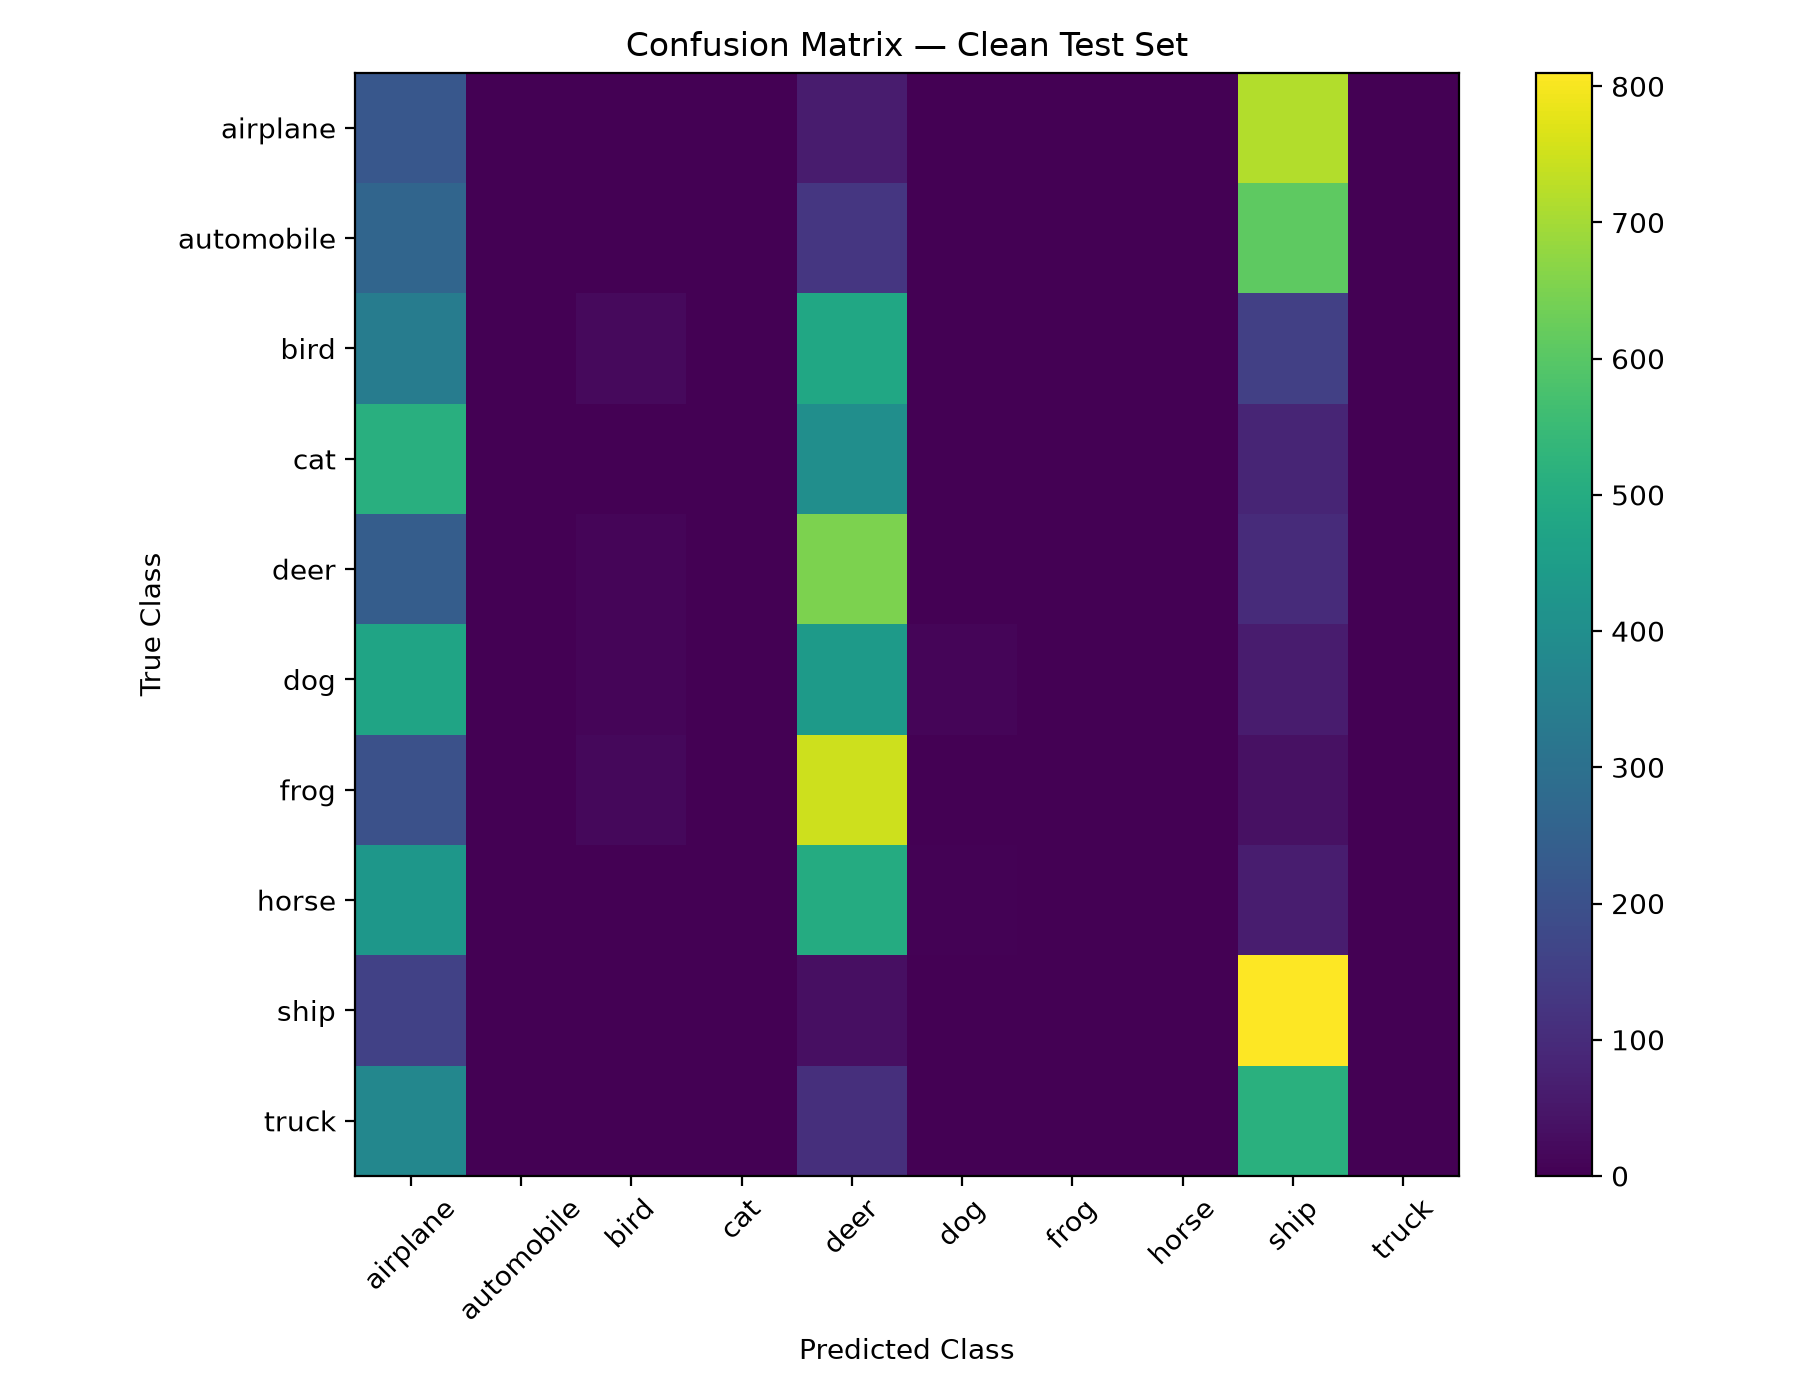

In [93]:
display(Image(filename="partE_confusion_matrix.png"))

In [95]:
# Part E — 8 Misclassified Images

misclassified_images = []
misclassified_labels = []
misclassified_predictions = []

final_model.eval()

with torch.no_grad():
    for images, labels in clean_test_loader:
        images_device = images.to(device)

        outputs = final_model(images_device)
        predictions = outputs.argmax(dim=1).cpu()

        for i in range(len(labels)):
            if predictions[i] != labels[i]:
                misclassified_images.append(images[i])
                misclassified_labels.append(labels[i].item())
                misclassified_predictions.append(predictions[i].item())

            if len(misclassified_images) >= 8:
                break

        if len(misclassified_images) >= 8:
            break

print(f"Collected {len(misclassified_images)} misclassified images.")

Collected 8 misclassified images.


In [96]:
# Part E — Display 8 Misclassified Images

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

for i, ax in enumerate(axes.flat):
    image = misclassified_images[i] * std + mean
    image = torch.clamp(image, 0, 1)

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(
        f"True: {class_names[misclassified_labels[i]]}\n"
        f"Pred: {class_names[misclassified_predictions[i]]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.savefig("partE_misclassified_8.png", dpi=200)
plt.close()

print("Saved 8 misclassified images to partE_misclassified_8.png")


Saved 8 misclassified images to partE_misclassified_8.png


## 8 misclassified images

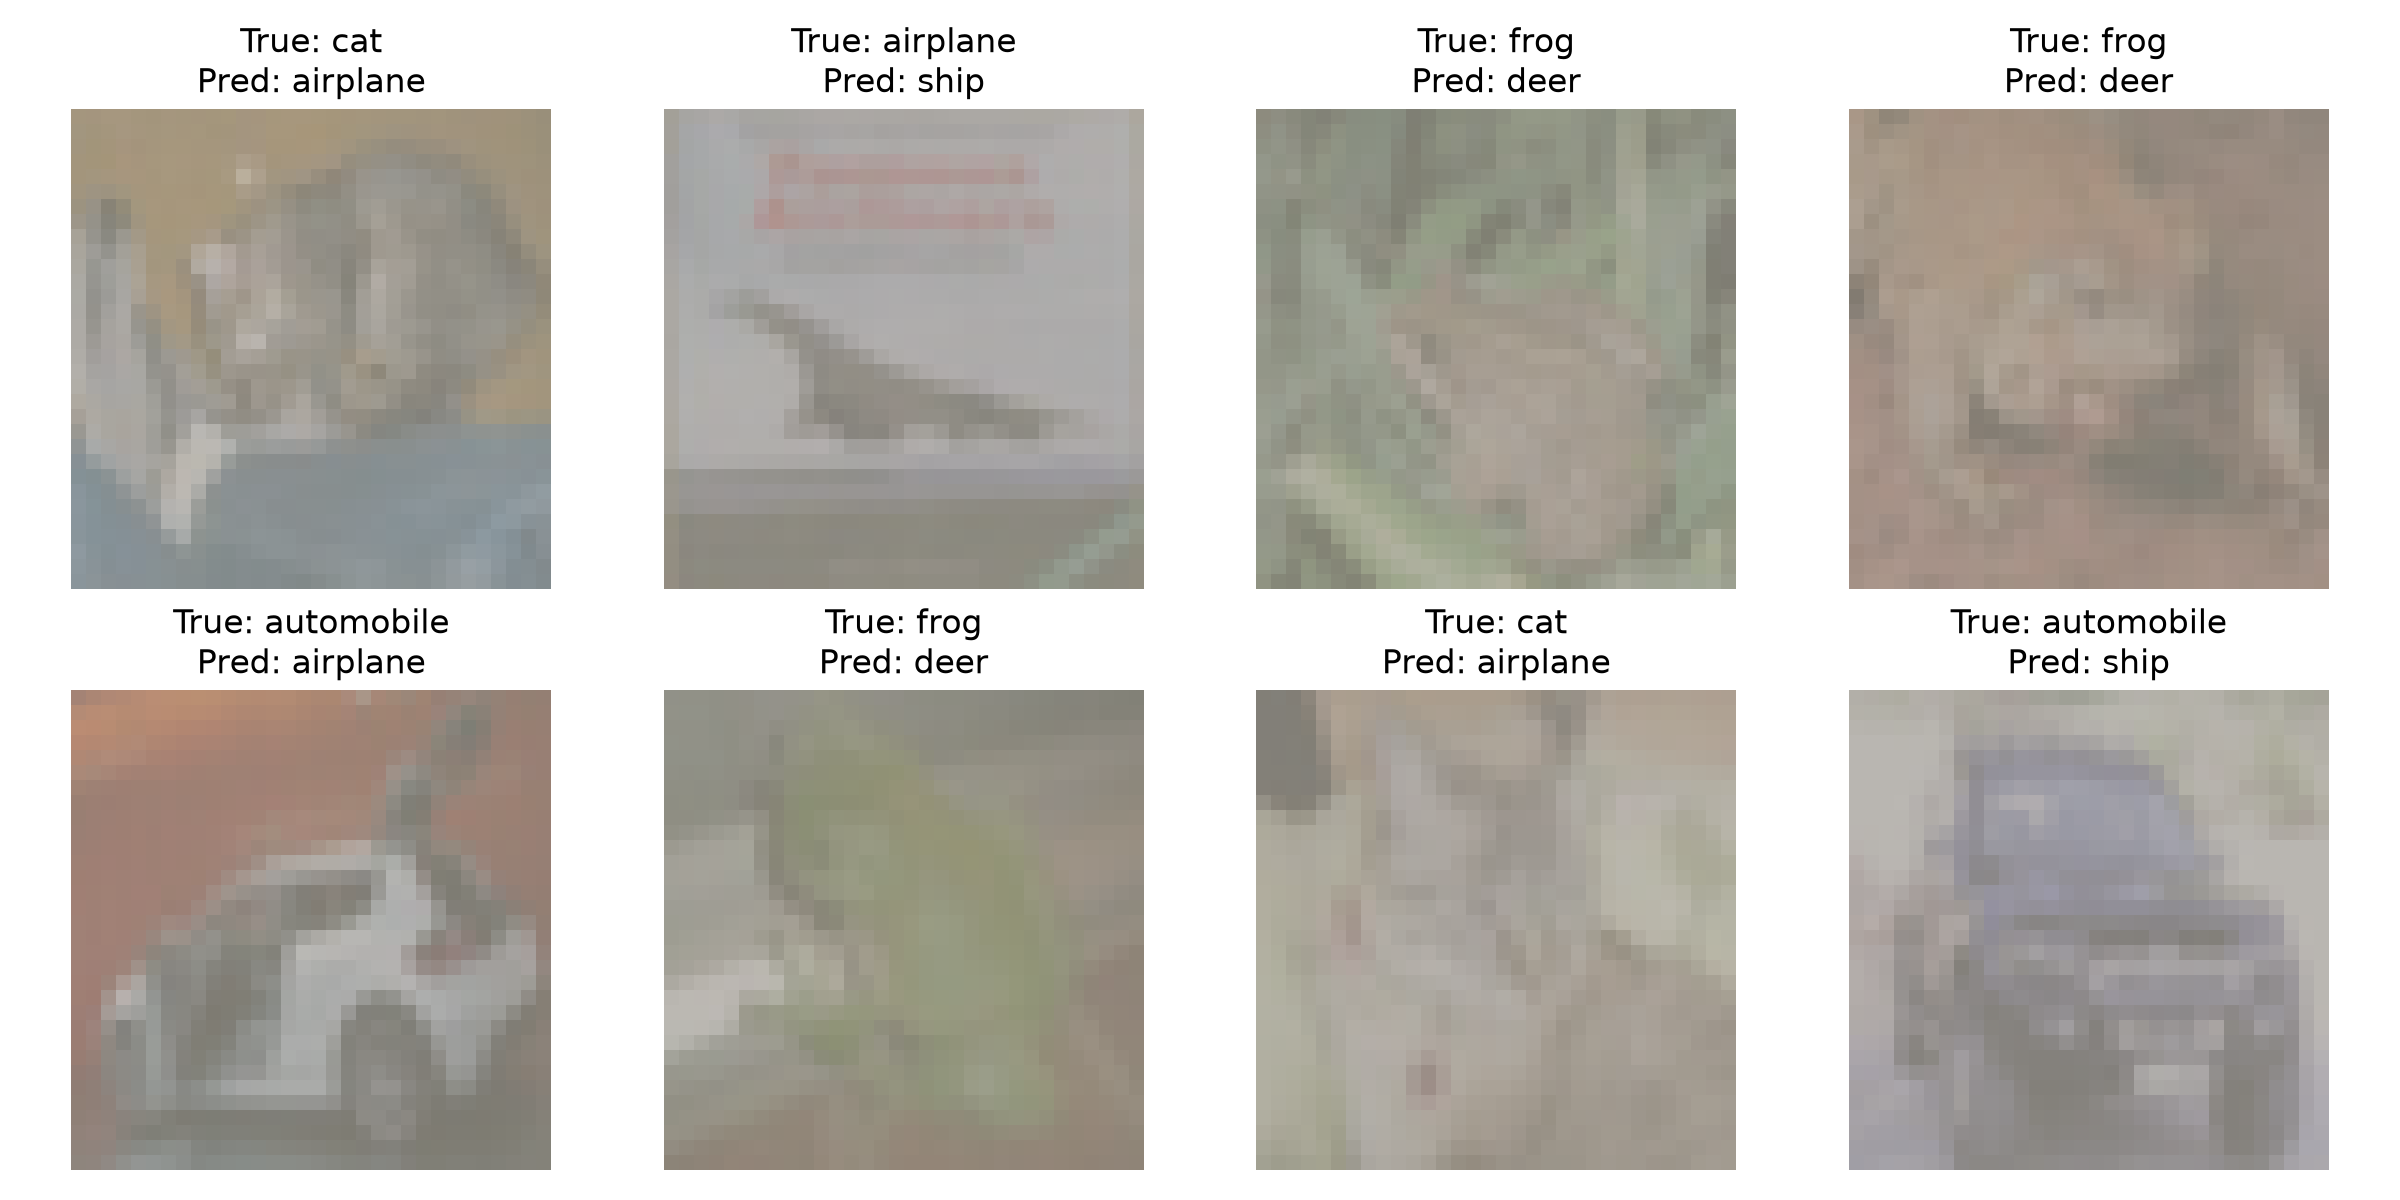

In [98]:
display(Image(filename="partE_misclassified_8.png"))

### Hidden Corruption Evaluation

The model was evaluated for robustness under distribution shifts using the
shifted CIFAR-10 test set. The evaluation included rotation, brightness and
contrast changes, and approximately 25% rectangular occlusion. These
transformations were applied using a fixed random seed to ensure reproducible
evaluation.

The results demonstrate how well the trained model generalizes beyond the
original clean test distribution.

### Part F — Bonus: Test-Time Augmentation (TTA)

Test-Time Augmentation (TTA) applies multiple transformed versions of each
test image and combines the model predictions. This can improve robustness by
reducing sensitivity to individual image transformations.

In [99]:
# Part F — Test-Time Augmentation

def tta_predict(model, images):
    model.eval()

    # Original images
    outputs_original = model(images)

    # Horizontal flip
    flipped = torch.flip(images, dims=[3])
    outputs_flip = model(flipped)

    # Average predictions
    outputs = (outputs_original + outputs_flip) / 2.0

    return outputs


def evaluate_tta(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = tta_predict(model, images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100.0 * correct / total


tta_clean_acc = evaluate_tta(final_model, clean_test_loader)
tta_shifted_acc = evaluate_tta(final_model, shifted_test_loader)

print(f"TTA Clean Test Accuracy: {tta_clean_acc:.2f}%")
print(f"TTA Shifted Test Accuracy: {tta_shifted_acc:.2f}%")

TTA Clean Test Accuracy: 17.12%
TTA Shifted Test Accuracy: 27.57%


### Part F — TTA Results and Conclusion

Test-Time Augmentation (TTA) was evaluated by combining predictions from the
original image and a horizontally flipped version.

Using the final model, TTA achieved 17.12% accuracy on the clean test set and
27.57% accuracy on the shifted test set.

The results show that horizontal-flip TTA provided a small improvement in
clean-test performance for the final analysis model, while shifted-test
performance remained slightly below the overall 3-seed final-model result.